In [1]:
import pandas as pd
import numpy as np
import os

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [3]:
DATA_DIR = r"F:\EDAIC-WOZ\data"
LABEL_DIR = r"F:\EDAIC-WOZ\labels"

print("Data directory:", DATA_DIR)
print("Label directory:", LABEL_DIR)

print("Data folder exists:", os.path.exists(DATA_DIR))
print("Label folder exists:", os.path.exists(LABEL_DIR))

Data directory: F:\EDAIC-WOZ\data
Label directory: F:\EDAIC-WOZ\labels
Data folder exists: True
Label folder exists: True


In [5]:
train_labels = pd.read_csv(
    os.path.join(LABEL_DIR, "train_split.csv")
)

print("Train shape:", train_labels.shape)

print("\nColumns:")
print(train_labels.columns.tolist())

print("\nFirst 5 rows:")
display(train_labels.head())

Train shape: (163, 6)

Columns:
['Participant_ID', 'Gender', 'PHQ_Binary', 'PHQ_Score', 'PCL-C (PTSD)', 'PTSD Severity']

First 5 rows:


,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity
0,302,male,0,4,0,28
1,303,female,0,0,0,17
2,304,female,0,6,0,20
3,305,male,0,7,0,28
4,307,female,0,4,0,23


In [7]:
print("PHQ_Binary class distribution:")

print(
    train_labels["PHQ_Binary"]
    .value_counts()
    .sort_index()
)

print("\nClass percentages:")

print(
    train_labels["PHQ_Binary"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

PHQ_Binary class distribution:
PHQ_Binary
0    126
1     37
Name: count, dtype: int64

Class percentages:
PHQ_Binary
0    77.3
1    22.7
Name: proportion, dtype: float64


In [9]:
def extract_mfcc(pid):
    pid = int(pid)

    feature_path = os.path.join(
        DATA_DIR,
        f"{pid:03d}_P",
        "features",
        f"{pid:03d}_BoAW_openSMILE_2.3.0_MFCC.csv"
    )

    df = pd.read_csv(feature_path, header=None)

    # Remove metadata columns
    features = df.iloc[:, 2:]

    # Calculate mean and standard deviation for each MFCC feature
    mean_features = features.mean(axis=0)
    std_features = features.std(axis=0)

    # Combine mean + std
    participant_features = np.concatenate([
        mean_features.values,
        std_features.values
    ])

    return participant_features

In [11]:
X_list = []
y_list = []
participant_ids = []

for _, row in train_labels.iterrows():
    pid = row["Participant_ID"]

    try:
        features = extract_mfcc(pid)

        X_list.append(features)
        y_list.append(row["PHQ_Binary"])
        participant_ids.append(pid)

    except Exception as e:
        print(f"Error for participant {pid}: {e}")

X = np.array(X_list)
y = np.array(y_list)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (163, 200)
y shape: (163,)


In [13]:
print("NaN values:", np.isnan(X).sum())
print("Inf values:", np.isinf(X).sum())
print("Data type:", X.dtype)
print("Number of participants:", X.shape[0])
print("Number of features:", X.shape[1])

NaN values: 0
Inf values: 0
Data type: float64
Number of participants: 163
Number of features: 200


In [15]:
model = Pipeline([
    ("selector", SelectKBest(score_func=f_classif, k=10)),
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

In [17]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

f1_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print("Fold F1 scores:", f1_scores)
print(f"Mean F1: {f1_scores.mean():.4f}")
print(f"Std F1:  {f1_scores.std():.4f}")
print(f"F1 Score: {f1_scores.mean():.4f} ± {f1_scores.std():.4f}")

Fold F1 scores: [0.23529412 0.25       0.30769231 0.38095238 0.38095238]
Mean F1: 0.3110
Std F1:  0.0620
F1 Score: 0.3110 ± 0.0620


In [19]:
oof_predictions = cross_val_predict(
    model,
    X,
    y,
    cv=cv
)

print(
    "Out-of-fold predictions shape:",
    oof_predictions.shape
)

Out-of-fold predictions shape: (163,)


In [21]:
print("Classification Report:")

print(
    classification_report(
        y,
        oof_predictions,
        target_names=[
            "Non-Depressed",
            "Depressed"
        ]
    )
)

Classification Report:
               precision    recall  f1-score   support

Non-Depressed       0.79      0.62      0.69       126
    Depressed       0.25      0.43      0.32        37

     accuracy                           0.58       163
    macro avg       0.52      0.53      0.51       163
 weighted avg       0.67      0.58      0.61       163



Confusion Matrix:
[[78 48]
 [21 16]]


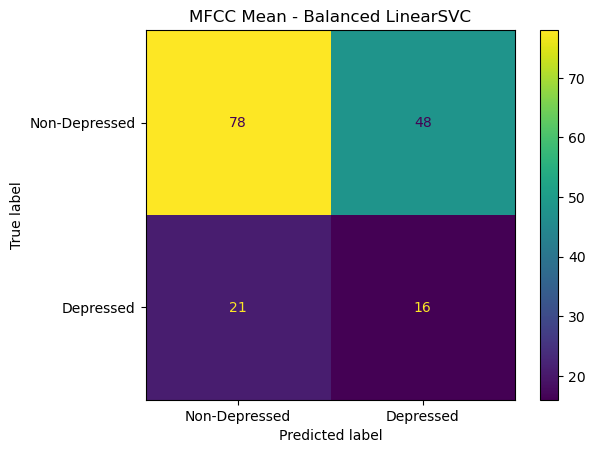

In [23]:
cm = confusion_matrix(
    y,
    oof_predictions
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Non-Depressed",
        "Depressed"
    ]
)

disp.plot()

plt.title("MFCC Mean - Balanced LinearSVC")
plt.show()

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Out-of-fold predictions
y_pred = cross_val_predict(
    model,
    X,
    y,
    cv=cv,
    method="predict"
)

# Final metrics
mean_f1 = f1_scores.mean()
std_f1 = f1_scores.std()

accuracy = accuracy_score(y, y_pred)
dep_precision = precision_score(y, y_pred, pos_label=1)
dep_recall = recall_score(y, y_pred, pos_label=1)
dep_f1 = f1_score(y, y_pred, pos_label=1)

# Results table
results = pd.DataFrame([{
    "Model": "LinearSVC + Balanced Class Weight",
    "Features": "MFCC Mean + Std",
    "Input Features": X.shape[1],
    "Selected Features": 10,
    "CV Folds": 5,
    "Mean F1": mean_f1,
    "Std F1": std_f1,
    "Accuracy": accuracy,
    "Depressed Precision": dep_precision,
    "Depressed Recall": dep_recall,
    "Depressed F1": dep_f1
}])

results

,Model,Features,Input Features,Selected Features,CV Folds,Mean F1,Std F1,Accuracy,Depressed Precision,Depressed Recall,Depressed F1
0,LinearSVC + Balanced Class Weight,MFCC Mean + Std,200,10,5,0.310978,0.062048,0.576687,0.25,0.432432,0.316832
